# EDA - Titanic
Create an account on kaggle.com and read the overview of the titanic competition at https://www.kaggle.com/c/titanic/overview, do the followings:

In [1]:
# import required packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# set matplotlib inline and use seaborn 
%matplotlib inline 

Download the training dataset and rename it to titanic-train.csv and load it using pandas

In [2]:
# download the training dataset "train.csv", rename it "titanic-train.csv" and load it using pandas
df_train = pd.read_csv('../data/titanic_train.csv')
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


- How many rows and features in the dataset?
- Which variable is the target for prediction? 
- Are there any null values? If yes, in which columns and how many?
- What are the data types of each feature?

In [3]:
# shape
df_train.shape

(891, 12)

In [4]:
# 'Survived' is the target

In [5]:
# are there any null values? if yes, in which columns and how many?
df_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

- Drop the columns with null values from the dataframe
- Print out the info of the data frame after dropping the columns. How many columns are left?

In [6]:
df_train.drop(columns=['Age','Cabin','Embarked'], inplace=True)
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    object 
 8   Fare         891 non-null    float64
dtypes: float64(1), int64(5), object(3)
memory usage: 62.8+ KB


- Plot the Histograms for all numerical features with figure size 10x10
- Discribe each histogram and state any findings you may have for each

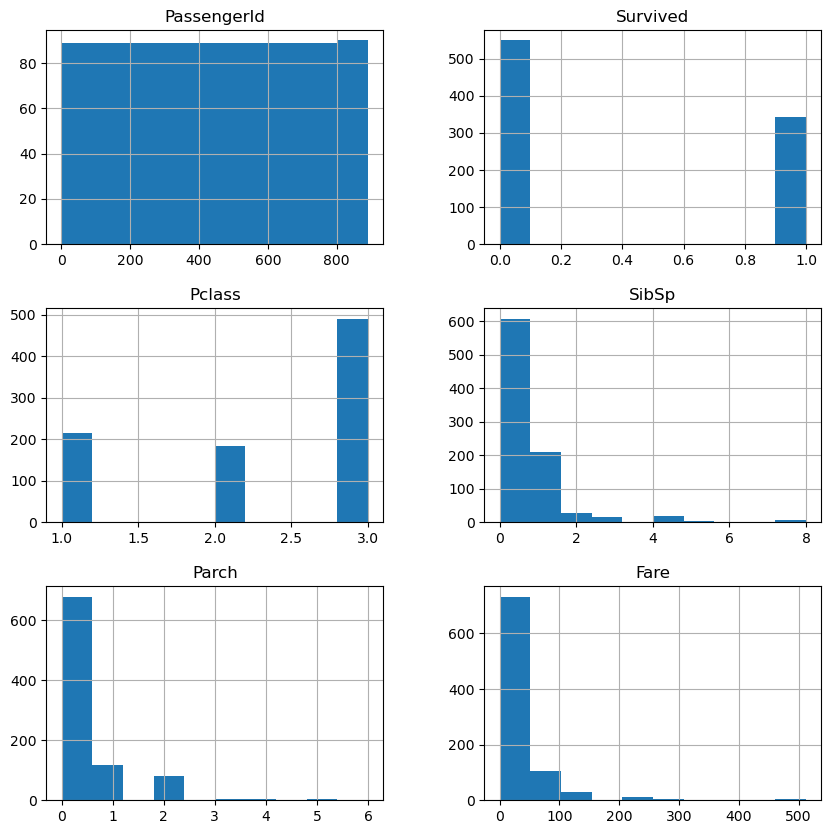

In [7]:
df_train.hist(figsize=(10,10))
plt.show()

- Calculate the overall suvival rate: # of survival / total # of passengers
- Use python script. Do not hardcode any number.

In [8]:
survival = df_train.Survived.value_counts()
survival[1]/sum(survival)

np.float64(0.3838383838383838)

In [9]:
df_train.Survived.value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

- Create a bar chart for gender
- Calculate the survival rate based on gender using `groupby()`

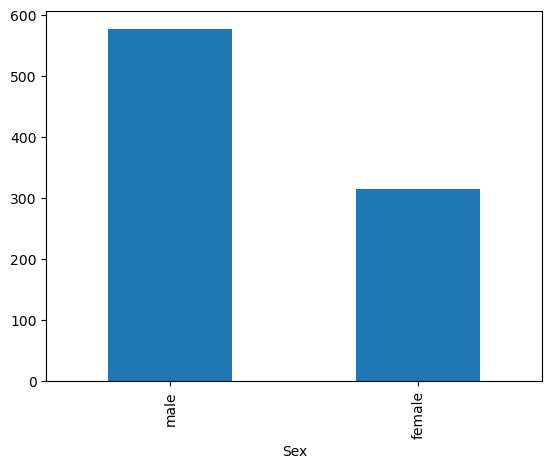

In [10]:
df_train.Sex.value_counts().plot(kind='bar')
plt.show()

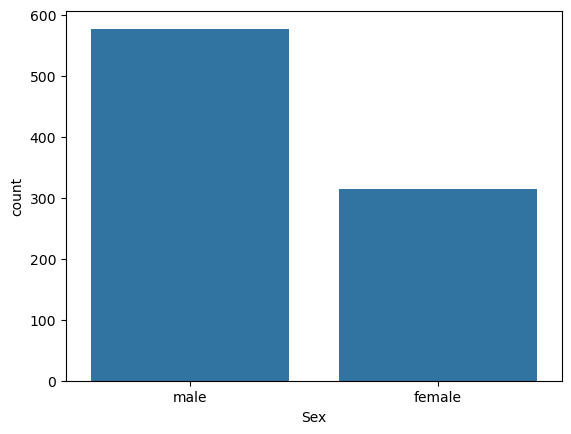

In [11]:
sns.countplot(data=df_train, x='Sex')
plt.show()

In [12]:
(
    df_train
    .pivot_table(values='PassengerId', index='Sex', columns='Survived', aggfunc='count')
    .reset_index()
    .rename(columns={0:'Survied_no',1:'Survied_yes'})
)

Survived,Sex,Survied_no,Survied_yes
0,female,81,233
1,male,468,109


In [13]:
df_train.groupby('Sex').agg({'PassengerId':'count','Survived':'sum'})

,PassengerId,Survived
Sex,,
female,314,233
male,577,109


In [14]:
# calculate the survival rate based on gender using groupby()
df1=df_train.groupby('Sex').agg({'PassengerId':'count','Survived':'sum'})
gender_survival_rate = df1['Survived']/df1['PassengerId']
gender_survival_rate

Sex
female    0.742038
male      0.188908
dtype: float64

In [15]:
(
    df_train.groupby(['Sex','Survived'])
    .agg({'PassengerId': 'count'})
    .groupby('Sex')
    .apply(lambda x: 100 * x / float(x.sum()))
)

C:\Users\lij9\AppData\Local\Temp\ipykernel_26156\2693288773.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  .apply(lambda x: 100 * x / float(x.sum()))


PassengerId
Sex    Sex    Survived             
female female 0           25.796178
              1           74.203822
male   male   0           81.109185
              1           18.890815

In [16]:
df_train.groupby('Sex').Survived.value_counts(normalize=True)

Sex     Survived
female  1           0.742038
        0           0.257962
male    0           0.811092
        1           0.188908
Name: proportion, dtype: float64

-  Based on the histograms above - choose features that you think may have outliers and create boxplots for those features to verify

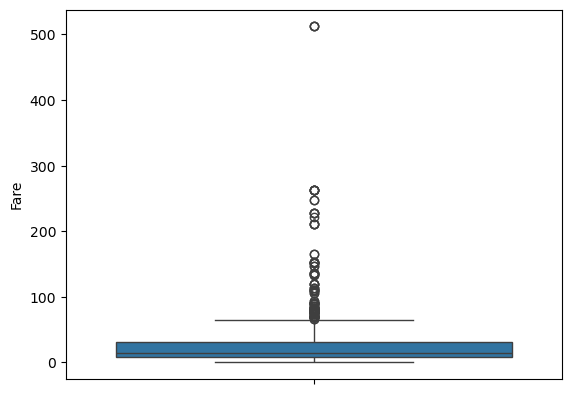

In [17]:
g=sns.boxplot(data=df_train, y='Fare')
#g.set_yscale("log")

plt.show()

- Create a scatter plot for `Fare` feature to take a closer look at the data points. Hint: use `df.index` as x and use values of `Fare` as y
- By eye-balling the scatter chart - how many tickets are over $500?

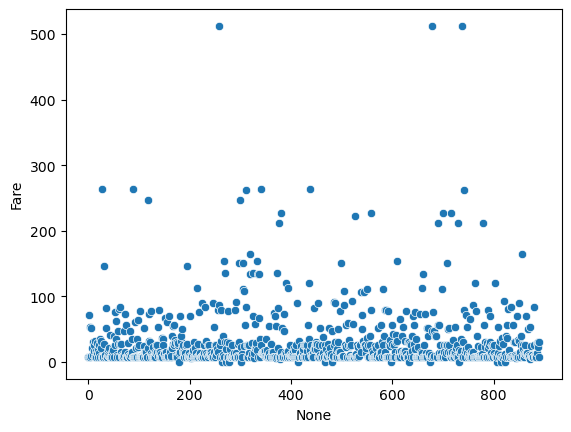

In [18]:
sns.scatterplot(data=df_train, x=df_train.index, y='Fare')
plt.show()

- Create plots check if there are any covariations among fare, # of siblings/spouses aboard, and survival?

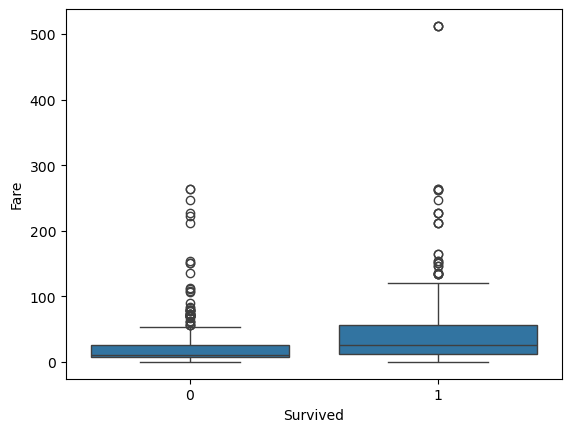

In [19]:
g=sns.boxplot(data=df_train, x='Survived', y='Fare')
#g.set_yscale("log")
plt.show()

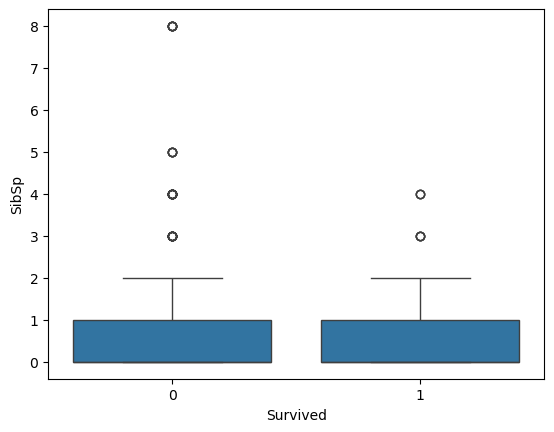

In [20]:
g=sns.boxplot(data=df_train, x='Survived', y='SibSp')
#g.set_yscale("log")
plt.show()